# Bump Chart

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Plots each item's rank (not its value) over several periods, with rank 1 at the top. Overtakes and changes in standing are easy to follow even when the underlying values are close.

## When to use

- Track rank changes over several periods (league tables, top-10 charts)
- Show the ranking itself rather than the gaps between values

## Avoid when

- The size of the gaps between items matters (ranks hide it)
- There are many items that swap places constantly (spaghetti)

## Alternatives

- Slope chart (two periods)
- Line chart of values

## Design tips

- Highlight two or three items of interest and gray the rest
- Label lines at the right end instead of using a legend

## Example

League position of 8 football clubs over 6 seasons, highlighting 3 clubs.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
seasons = ["18/19", "19/20", "20/21", "21/22", "22/23", "23/24"]
ranks = {
    "Rovers":   [1, 1, 2, 3, 5, 6],
    "United":   [5, 4, 3, 1, 1, 2],
    "City":     [2, 2, 1, 2, 3, 1],
    "Athletic": [8, 7, 6, 5, 2, 3],
    "Wanderers":[3, 3, 4, 4, 4, 4],
    "Albion":   [4, 5, 5, 7, 6, 5],
    "Town":     [6, 8, 8, 6, 7, 8],
    "Rangers":  [7, 6, 7, 8, 8, 7],
}
df = pd.DataFrame(ranks, index=seasons)
df

,Rovers,United,City,Athletic,Wanderers,Albion,Town,Rangers
18/19,1,5,2,8,3,4,6,7
19/20,1,4,2,7,3,5,8,6
20/21,2,3,1,6,4,5,8,7
21/22,3,1,2,5,4,7,6,8
22/23,5,1,3,2,4,6,7,8
23/24,6,2,1,3,4,5,8,7


### Plot

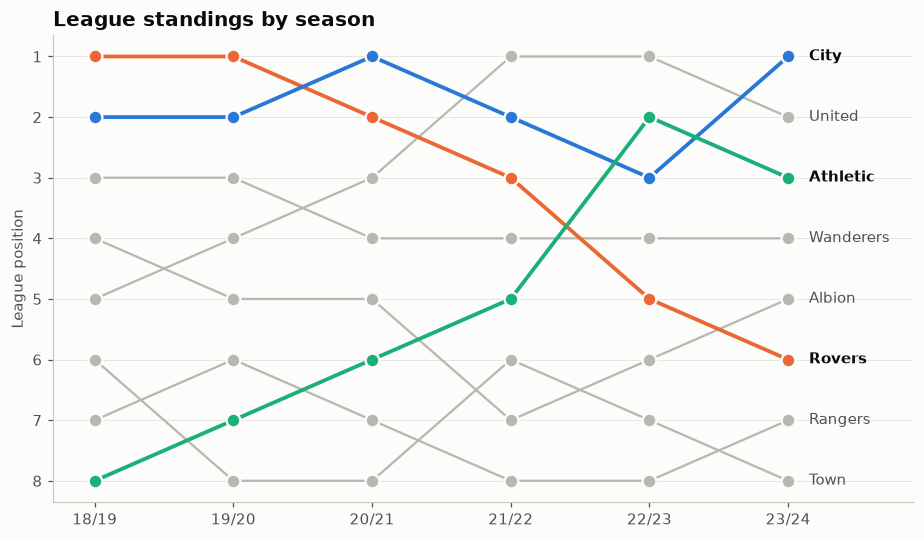

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5))
highlight = {"Rovers": PALETTE[1], "Athletic": PALETTE[2], "City": PALETTE[0]}
x = np.arange(len(df))
for team in df.columns:
    color = highlight.get(team, GRAY)
    z, lw = (3, 2.5) if team in highlight else (1, 1.5)
    ax.plot(x, df[team], color=color, linewidth=lw, marker="o", markersize=9,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, zorder=z)
    ax.text(x[-1] + 0.15, df[team].iloc[-1], team, va="center", fontsize=9.5,
            color="#0b0b0b" if team in highlight else "#52514e",
            weight="bold" if team in highlight else "normal")
ax.set_yticks(range(1, 9))
ax.invert_yaxis()
ax.set_xticks(x, df.index)
ax.set_xlim(-0.3, len(df) - 0.1)
ax.set_ylabel("League position")
ax.set_title("League standings by season")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Higher on the chart means a better position. Athletic climbs steadily from 8th to 3rd, while Rovers slides from 1st to 6th.

---
Standalone script: [`bump_chart.py`](bump_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)